# Issue #285 — ticket miss distance and protection

The independent unit is a Beijing issue. Tickets, sampled subsets and stream
seeds are nested diagnostics. The notebook asks whether a protection choice
made before the result can locate a ticket's future wrong leg and earn more
than its extra stake. All values are pre-tax; 0.65 is applied once to a winning
complete N-fold. No 2024+ outcome is opened.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
RESULTS = ROOT / 'results/issue-285'
distance = pd.read_csv(RESULTS / 'near_miss_distance_summary.csv')
thin = pd.read_csv(RESULTS / 'protection_rule_summary.csv')
broad = pd.read_parquet(RESULTS / 'protection_confirmation_panel.parquet')
dense = pd.read_csv(RESULTS / 'n8-dense/dense_protection_summary.csv')
dense_panel = pd.read_parquet(
    RESULTS / 'n8-dense/protection_confirmation_panel.parquet'
)
dense_year = pd.read_csv(RESULTS / 'n8-dense/dense_protection_by_year.csv')
receipt = json.loads(
    (RESULTS / 'n8-dense/dense_analysis_receipt.json').read_text()
)
assert broad.issue_year.max() <= 2023
assert dense_panel.issue_year.max() <= 2023
{'broad_rows': len(broad), 'dense_rows': len(dense_panel), **receipt}

{'broad_rows': 87120,
 'dense_rows': 48440,
 'independent_unit': 'ISSUE',
 'nuisance_aggregation': 'MEAN_WITHIN_ISSUE_ACTION_ACROSS_SUBSET_AND_SEED',
 'bootstrap_replicates': 20000,
 'bootstrap_seed': 285999,
 'adverse_all_marginal_roi_negative': True,
 'adverse_localization_beats_random': True,
 'decision': 'NO_BLANKET_PROTECTION_ADVANCE_SELECTIVE_LEARNING'}

## How close were the original N9/K64 tickets?

In [2]:
distance

,miss_bucket,tickets,share,issue_count
0,0,6,0.000155,606
1,1,81,0.002088,606
2,2,516,0.013304,606
3,3+,38181,0.984452,606


In [3]:
thin[[
    'rule','marginal_protection_roi','ex_largest_marginal_roi',
    'missed_leg_localization_rate','single_flip_rescue_rate',
    'bootstrap_marginal_roi_p025','bootstrap_marginal_roi_p975'
]].sort_values('marginal_protection_roi', ascending=False)

,rule,marginal_protection_roi,ex_largest_marginal_roi,missed_leg_localization_rate,single_flip_rescue_rate,bootstrap_marginal_roi_p025,bootstrap_marginal_roi_p975
0,ADVERSE_SIGNED_DIVERGENCE,0.683437,0.172768,0.197531,0.172840,-0.442516,2.205777
1,LOW_MODEL_MARGIN,-0.263765,-0.554891,0.160494,0.123457,-0.857614,0.520796
2,LOW_SELECTED_PROBABILITY,-0.287192,-0.576139,0.160494,0.111111,-0.843747,0.480773
3,RANDOM_BUDGET_CONTROL,-0.314226,-0.548919,0.111111,0.074074,-0.847099,0.375811
4,HIGH_ENTROPY,-0.464660,-0.717734,0.061728,0.037037,-1.000000,0.286570


Only 81 of 38,784 base tickets missed by exactly one leg. The
thin adverse-divergence rule looked profitable and localized the missed leg
more often than random, but its interval crossed zero and one issue dominated.
That observation triggered nuisance confirmation; it did not freeze a
candidate.

## Broad N/K confirmation

In [4]:
keys = ['issue','issue_year','n','k','proposal_family','rule']
broad_issue = broad.groupby(keys, as_index=False).mean(numeric_only=True)
broad_curve = broad_issue.groupby(
    ['n','k','proposal_family','rule'], as_index=False
).agg(
    lift=('protection_lift_cny','sum'),
    stake=('extra_stake_cny','sum'),
    continuation=('continuation_lift_cny','sum'),
)
broad_curve['marginal_roi'] = broad_curve.lift / broad_curve.stake
broad_curve['excess_vs_continuation'] = (
    broad_curve.lift - broad_curve.continuation
) / broad_curve.stake
broad_curve.loc[
    broad_curve.rule.eq('ADVERSE_SIGNED_DIVERGENCE')
].sort_values('marginal_roi', ascending=False).head(12)

,n,k,proposal_family,rule,lift,stake,continuation,marginal_roi,excess_vs_continuation
12,8,16,DIVERGENCE_WEIGHTED,ADVERSE_SIGNED_DIVERGENCE,11686.821891,18380.000000,367.669757,0.635844,0.615841
38,10,16,UNIFORM,ADVERSE_SIGNED_DIVERGENCE,5826.002203,19255.333333,-41.645264,0.302566,0.304728
16,8,64,DIVERGENCE_WEIGHTED,ADVERSE_SIGNED_DIVERGENCE,15157.536974,64820.000000,-27035.515557,0.233840,0.650926
14,8,16,UNIFORM,ADVERSE_SIGNED_DIVERGENCE,2537.134900,18751.333333,-5846.100093,0.135304,0.447074
30,9,64,UNIFORM,ADVERSE_SIGNED_DIVERGENCE,3984.559350,73062.000000,7385.381984,0.054537,-0.046547
46,10,128,UNIFORM,ADVERSE_SIGNED_DIVERGENCE,-7654.099074,147902.000000,-5013.915735,-0.051751,-0.017851
34,9,128,UNIFORM,ADVERSE_SIGNED_DIVERGENCE,-8280.095209,139050.000000,149804.038983,-0.059548,-1.136887
20,8,128,DIVERGENCE_WEIGHTED,ADVERSE_SIGNED_DIVERGENCE,-10453.637944,114658.000000,-41395.917181,-0.091172,0.269866
6,7,64,UNIFORM,ADVERSE_SIGNED_DIVERGENCE,-6308.825336,59046.000000,-2475.453586,-0.106846,-0.064922
32,9,128,DIVERGENCE_WEIGHTED,ADVERSE_SIGNED_DIVERGENCE,-14656.426955,132421.333333,-10618.263049,-0.110680,-0.030495


The original N9/K64 cell reversed under three new stream seeds.
N8/K16 and N8/K64 survived the broad pass and were therefore the only cells
expanded to four subsets and five seeds.

## Dense N8 confirmation

In [5]:
display(dense[[
    'n','k','rule','marginal_protection_roi','ex_largest_marginal_roi',
    'protection_excess_roi_vs_continuation',
    'missed_leg_localization_rate','single_flip_rescue_rate','positive_years',
    'bootstrap_marginal_roi_p025','bootstrap_marginal_roi_p975',
    'bootstrap_adverse_minus_random_p025',
    'bootstrap_adverse_minus_random_p975'
]])
issue_localization = dense_panel.groupby(
    ['issue','issue_year','k','rule'], as_index=False
).agg(
    localized=('localized_near_miss_tickets','mean'),
    near_miss=('near_miss_tickets','mean'),
)
issue_localization = issue_localization.loc[issue_localization.near_miss.gt(0)]
issue_localization['issue_rate'] = (
    issue_localization.localized / issue_localization.near_miss
)
issue_localization.groupby(['k','rule'], as_index=False).agg(
    eligible_issues=('issue','nunique'),
    equal_issue_localization=('issue_rate','mean'),
)

,n,k,rule,marginal_protection_roi,ex_largest_marginal_roi,protection_excess_roi_vs_continuation,missed_leg_localization_rate,single_flip_rescue_rate,positive_years,bootstrap_marginal_roi_p025,bootstrap_marginal_roi_p975,bootstrap_adverse_minus_random_p025,bootstrap_adverse_minus_random_p975
0,8,16,ADVERSE_SIGNED_DIVERGENCE,-0.132055,-0.184193,0.032907,0.197214,0.119195,3,-0.387989,0.164179,-0.498869,0.414402
1,8,16,RANDOM_BUDGET_CONTROL,-0.107926,-0.218876,0.016466,0.114241,0.064087,3,-0.440601,0.300458,-0.498869,0.414402
2,8,64,ADVERSE_SIGNED_DIVERGENCE,-0.048702,-0.119114,0.104727,0.204044,0.134237,3,-0.236862,0.178160,-0.259172,0.311429
3,8,64,RANDOM_BUDGET_CONTROL,-0.071206,-0.118925,0.088821,0.113135,0.067400,4,-0.256836,0.139924,-0.259172,0.311429


,k,rule,eligible_issues,equal_issue_localization
0,16,ADVERSE_SIGNED_DIVERGENCE,443,0.151580
1,16,RANDOM_BUDGET_CONTROL,443,0.112335
2,64,ADVERSE_SIGNED_DIVERGENCE,600,0.152885
3,64,RANDOM_BUDGET_CONTROL,600,0.111269


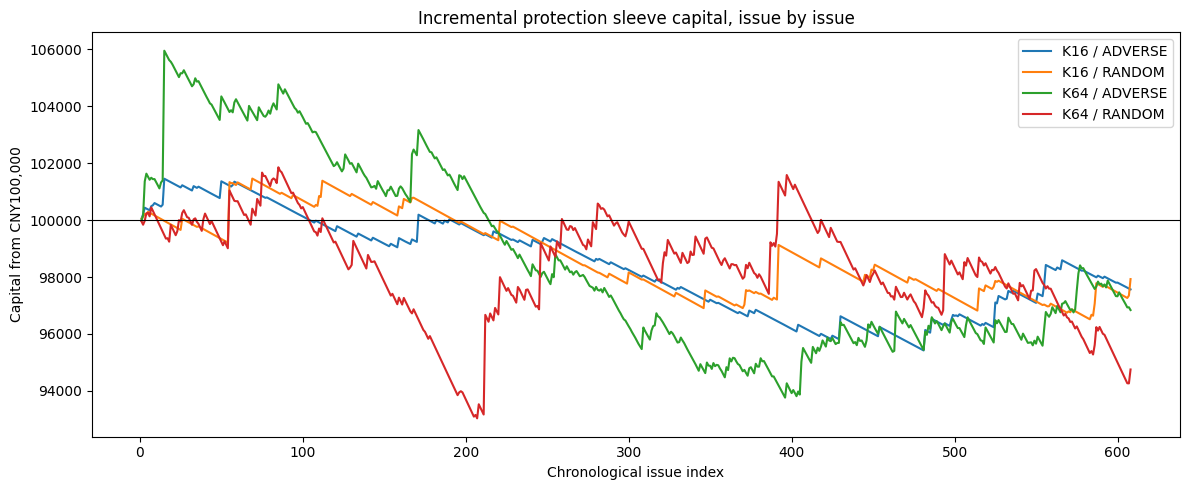

In [6]:
issue = dense_panel.groupby(
    ['issue','issue_year','k','rule'], as_index=False
).mean(numeric_only=True)
issue['issue_number'] = pd.to_numeric(issue.issue, errors='raise')
fig, ax = plt.subplots(figsize=(12,5))
for (k, rule), group in issue.groupby(['k','rule'], sort=True):
    group = group.sort_values(['issue_year','issue_number'])
    assert group.issue_year.is_monotonic_increasing
    capital = 100_000 + group.protection_lift_cny.cumsum()
    ax.plot(
        range(1, len(group)+1), capital,
        label=f'K{k} / {rule.replace("_BUDGET_CONTROL", "").replace("_SIGNED_DIVERGENCE", "")}'
    )
ax.axhline(100_000, color='black', linewidth=0.8)
ax.set(
    title='Incremental protection sleeve capital, issue by issue',
    xlabel='Chronological issue index', ylabel='Capital from CNY100,000'
)
ax.legend(); plt.tight_layout()

In [7]:
dense_year.loc[
    dense_year.rule.eq('ADVERSE_SIGNED_DIVERGENCE'),
    ['k','issue_year','marginal_protection_roi','excess_roi_vs_continuation']
].pivot(index='issue_year', columns='k')

marginal_protection_roi           excess_roi_vs_continuation  \
k                               16        64                         16   
issue_year                                                                
2014                     -0.128265  0.120273                  -0.091384   
2015                      0.319374 -0.046546                   0.573826   
2016                     -0.489450 -0.583335                   0.114140   
2017                     -0.555206 -0.159437                  -1.038408   
2018                     -0.680744 -0.440040                  -0.058850   
2019                     -0.631490 -0.169573                  -0.191350   
2020                      0.201773  0.586539                   0.324709   
2021                     -0.157967 -0.021598                  -0.613099   
2022                      0.751740 -0.016124                   1.381972   
2023                     -0.106041  0.120829                  -0.140378   

                      
k                 64  
issue_year            
2014        0.080054  
2015       -0.511178  
2016       -0.201476  
2017        0.556154  
2018       -0.503652  
2019        0.189737  
2020        1.139816  
2021        0.575619  
2022       -0.097198  
2023        0.224695

## Decision

Blanket protection does not advance: dense N8/K16 is −13.21% on incremental
capital and N8/K64 is −4.87%; both ex-largest results remain negative and both
issue-bootstrap intervals cross zero. Under equal issue weight,
adverse-divergence localization is 15.16%/15.29% for K16/K64 versus
11.23%/11.13% for random, a positive difference of about four percentage
points. The prior near-twofold magnitude was ticket-weighted and is withdrawn.
The information signal survives while the fixed-cost policy does not.

The justified successor is a selective-protection learner. Its target must be
the counterfactual incremental P&L of protecting a ticket, not a conditional
near-miss classification alone. It may abstain on most tickets and must fall
back to the unprotected base portfolio.